In [1]:
import sys
import os
import pickle
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# read_ids = list(range(0, 12+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
read_ids = [0]
plot_id = 0

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [6]:
plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

In [37]:
markers_c = [pd.DataFrame(marker.values - marker.values.mean(axis=0), columns=marker.columns) for marker in markers]

shift_s = 5
shift_a = shift_s * sampling_rates[plot_idx]
print(shift_a)

# for s in range(markers.shape[0] // 10):
#

58.86624641491395


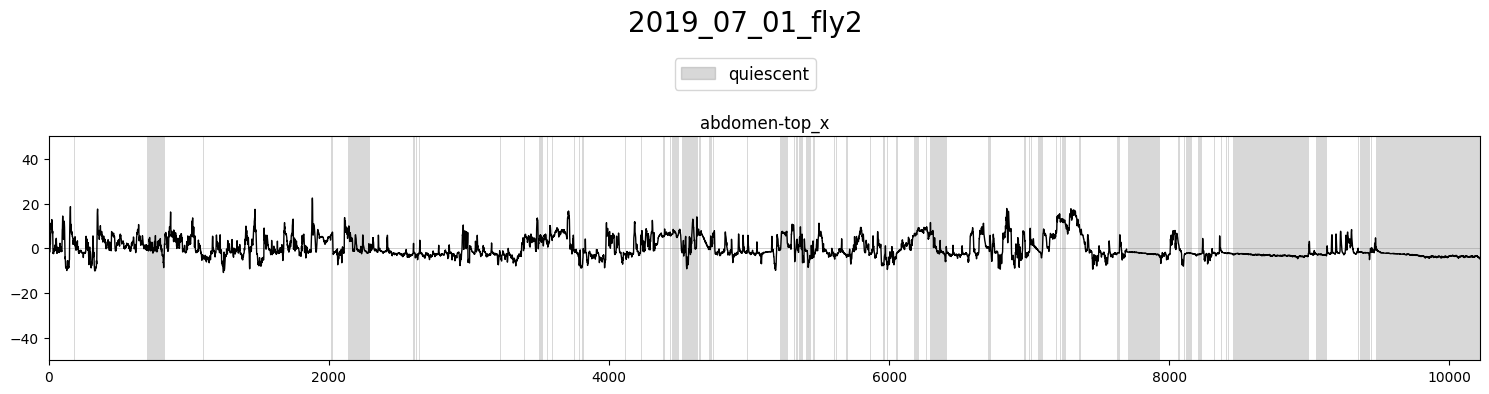

In [21]:
max_x = markers[plot_idx].values.shape[0]
# max_x = 1000

plot_utils.plot_traces(markers_c[plot_idx].iloc[:max_x, :1],
					   states[plot_idx]['still'].iloc[:max_x],
					   label='quiescent',
					   title=f'{filenames[plot_idx]}',
					   n_plots=1, plots_per_row=1, top_space=1, ylimits=(-50, 50))

In [9]:
print(traces[plot_idx].shape)

(10219, 1559)


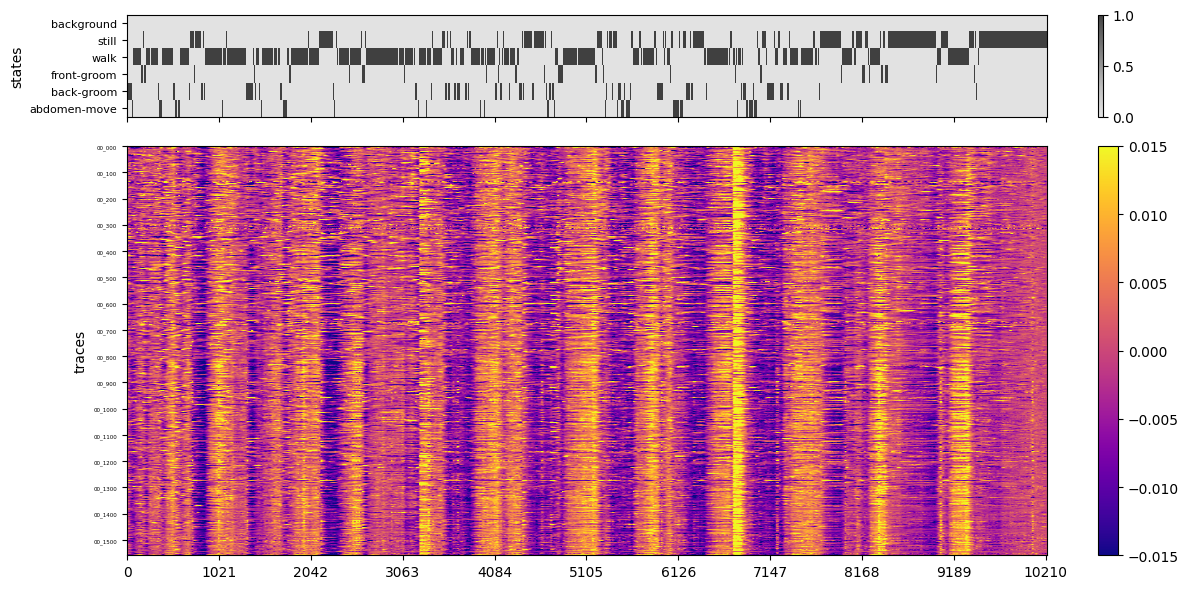

In [10]:
plot_utils.plot_heatmap_stack(
	traces[plot_idx], states[plot_idx],
	'traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

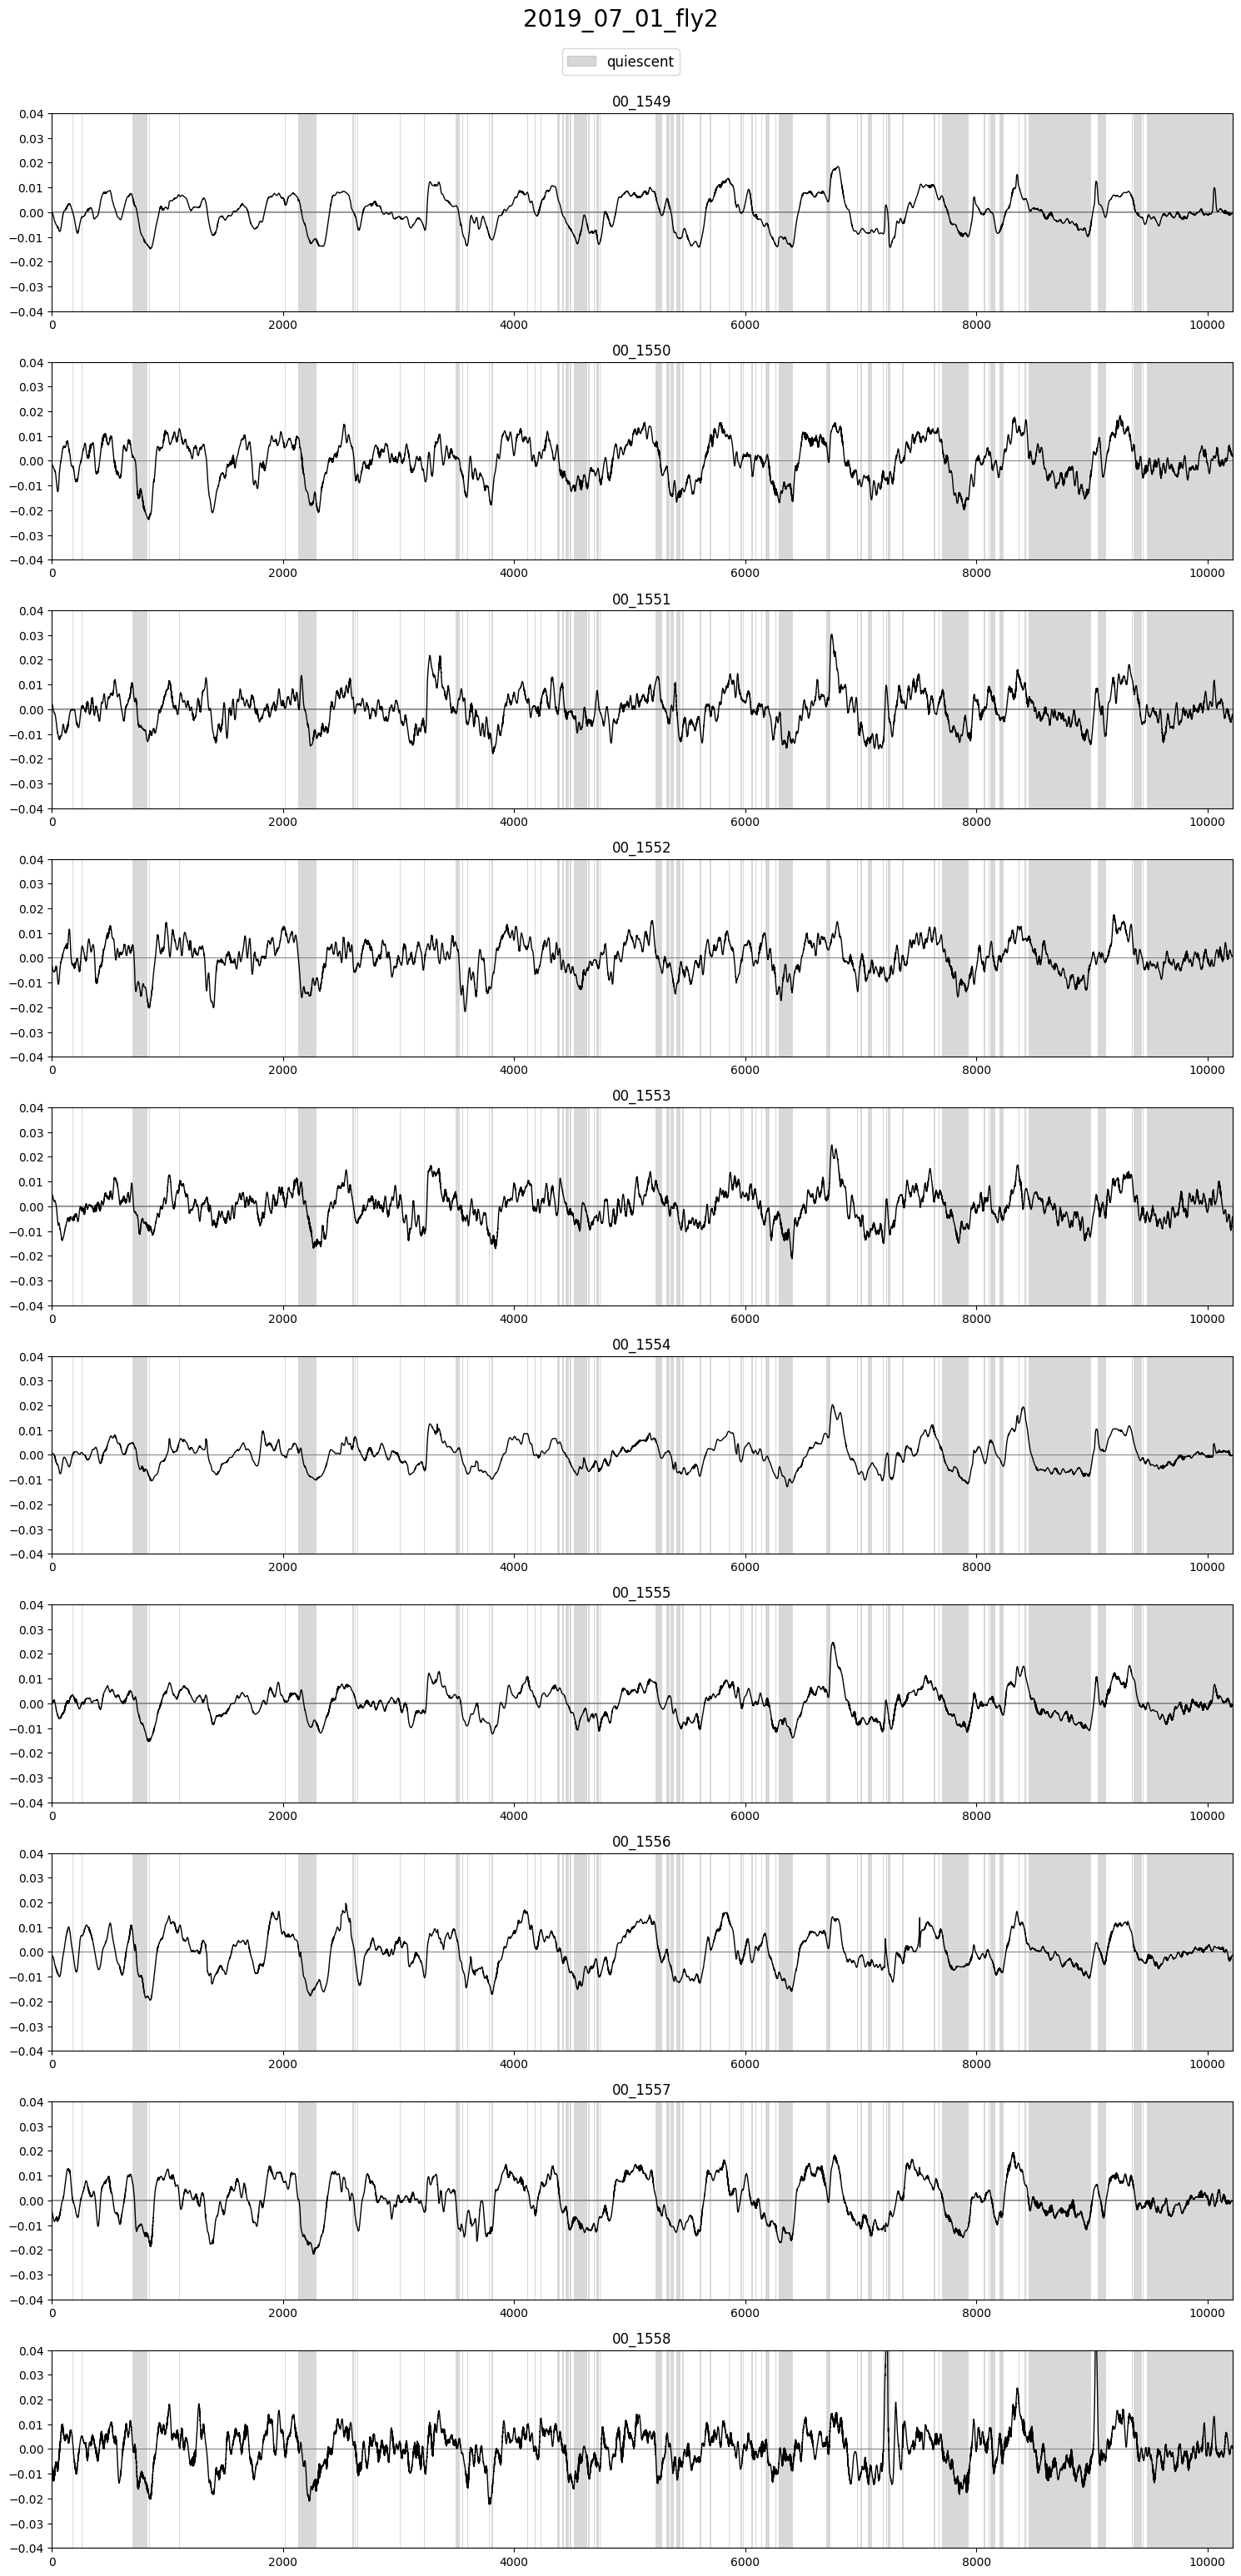

In [11]:
plot_utils.plot_traces(traces[plot_idx].iloc[:, -10:],
					   states[plot_idx]['still'],
					   label='quiescent',
					   title=f'{filenames[plot_idx]}',
					   n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))

# flail

In [12]:
# read_ids_fl = list(range(0, 9+1))
read_ids_fl = [1, 4, 5]
plot_id_fl = 4

In [13]:
path_fl = os.path.join(read_utils.get_data_path(), 'brain/incomplete/no_pickle/flailing')

(file_ids_fl, filenames_fl,
 traces_fl,
 states_fl, markers_fl) = read_utils.get_datas(path_fl, read_ids_fl, with_markers=False)

# # clear nan values
# for i in range(len(file_ids_fl)):
# 	mask = markers_fl[i].notna().all(axis=1)
#
# 	traces_fl[i] = traces_fl[i][mask]
# 	markers_fl[i] = markers_fl[i][mask]
# 	states_fl[i] = states_fl[i][mask]
#
# 	#filenames_fl[i] = filenames_fl[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids_fl)):
	traces_fl[i].columns = pd.Index([
		f'{file_ids_fl[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_fl[i].columns, traces_fl[i].columns == ''))
	])

IndexError: list index out of range

In [ ]:
plot_idx_fl = file_ids_fl.index(plot_id_fl)

# states)fl = [ds[selection_bhl] for ds in states_fl]

In [ ]:
print(traces_fl[plot_idx_fl].shape)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_fl[plot_idx_fl], states_fl[plot_idx_fl][['?']],
	'traces flailing', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False, height_ratios=(1, 16))

In [ ]:
plot_utils.plot_traces(traces_fl[plot_idx_fl].iloc[:, -10:],
					   states_fl[plot_idx_fl]['?'],
					   label='?',
					   title=f'{filenames_fl[plot_idx_fl]}',
					   n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))